In [8]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
ROI_DIR = RAW / "BOLD5000_GLMsingle_ROI_betas" / "py"
EVENT_DIR = RAW / "BOLD5000_metadata" / "CSI1_events"
LIST_DIR = RAW / "BOLD5000_metadata" / "CSI1_presentation_lists"
IMAGE_DIR = RAW / "BOLD5000_Stimuli_samples" / "Presented_Stimuli"

print("CSI1 event files:", len(list(EVENT_DIR.glob("*_events.tsv"))))

CSI1 event files: 142


## What the ten response files mean

There are **5 regions × 2 sides of the brain = 10 files**. `LH` means left hemisphere and `RH` means right hemisphere. These files are split by region and side. 

| Region | Common research focus (roughly) |
|---|---|
| EarlyVis | Early visual processing |
| LOC | Objects and shapes |
| OPA, PPA, RSC | Scenes and places |

These are broad research associations, not strict rules about what a region can respond to.

Each file is a table: **rows = image showings; columns = selected voxels** in that region and hemisphere. For example, left EarlyVis has shape `(5254, 210)`: 5,254 showings and 210 voxels.

In [9]:
roi_names = ["EarlyVis", "LOC", "OPA", "PPA", "RSC"]
arrays, records = {}, []
for path in sorted(ROI_DIR.glob("CSI1*_allses_*.npy")):
    match = re.search(r"_allses_(LH|RH)(EarlyVis|LOC|OPA|PPA|RSC)\.npy$", path.name)
    if match is None:
        continue
    hemi, roi = match.groups()
    key = f"{hemi}_{roi}"
    arrays[key] = np.load(path)
    records.append({"Hemisphere": hemi, "ROI": roi,
                    "Showings (rows)": arrays[key].shape[0],
                    "Voxels (columns)": arrays[key].shape[1],
                    "Type": str(arrays[key].dtype)})

order = [f"{hemi}_{roi}" for roi in roi_names for hemi in ["LH", "RH"]]
summary = pd.DataFrame(records).sort_values(["ROI", "Hemisphere"]).reset_index(drop=True)
display(summary)
X = np.concatenate([arrays[key] for key in order], axis=1)
print(f"Combined: {X.shape[0]:,} showings × {X.shape[1]:,} ROI voxel columns; {X.dtype}; {X.nbytes / 1024**2:.2f} MiB")
left_total = int(summary.loc[summary["Hemisphere"] == "LH", "Voxels (columns)"].sum())
right_total = int(summary.loc[summary["Hemisphere"] == "RH", "Voxels (columns)"].sum())
print(f"Column-count total: {left_total} left + {right_total} right = {left_total + right_total} ROI voxel columns.")

,Hemisphere,ROI,Showings (rows),Voxels (columns),Type
0,LH,EarlyVis,5254,210,float32
1,RH,EarlyVis,5254,285,float32
2,LH,LOC,5254,152,float32
3,RH,LOC,5254,190,float32
4,LH,OPA,5254,101,float32
5,RH,OPA,5254,187,float32
6,LH,PPA,5254,131,float32
7,RH,PPA,5254,200,float32
8,LH,RSC,5254,86,float32
9,RH,RSC,5254,143,float32


Combined: 5,254 showings × 1,685 ROI voxel columns; float32; 33.77 MiB
Column-count total: 680 left + 1005 right = 1685 ROI voxel columns.


## What is one voxel value?

A voxel is a tiny 3D spot in the brain. Its location stays the same in its region and hemisphere. For each image showing, the table stores **one response number for that spot**. So the voxel has a 3D location, but its response here is a single number, not a 3D image.

In [10]:
files = sorted(EVENT_DIR.glob("*_events.tsv"), key=lambda p: tuple(int(n) for n in re.findall(r"(?:ses-|run-)(\d+)", p.name)))
frames = []

for path in files:
    frame = pd.read_csv(path, sep="\t")
    frame["event_file"] = path.name
    frames.append(frame)
events = pd.concat(frames, ignore_index=True)

for col in ["Sess", "Run", "Trial"]:
    events[col] = pd.to_numeric(events[col]).astype(int)

events = events.sort_values(["Sess", "Run", "Trial"]).reset_index(drop=True)
events["brain_row"] = np.arange(len(events))

print("Session = 1–15; run = 1–9 or 1–10 within a session; trial = 1–37 within a run.")
print("brain_row = overall row 0–5253. The 10 files do not number the rows.")

events["source"] = events["ImgType"].astype(str).str.replace(r"^rep_", "", regex=True).str.lower()
counts = events["ImgName"].value_counts()
events["showings_of_image"] = events["ImgName"].map(counts)
events["repeated"] = events["showings_of_image"] > 1

assert len(events) == X.shape[0] == 5254
print(f"Event rows: {len(events):,} | distinct image IDs: {events['ImgName'].nunique():,}")
print(f"Repeated image IDs: {int((counts > 1).sum())} | their response rows: {int(counts[counts > 1].sum())}")

session_counts = events.groupby("Sess").size().rename("Showings")
repeat_counts = counts.value_counts().sort_index().rename_axis("Showings per image").rename("Distinct images")
source_counts = events.groupby("source")["ImgName"].nunique().rename("Distinct images")
display(pd.concat([session_counts.rename_axis("Session").to_frame(),], axis=1))
display(repeat_counts.to_frame())
display(source_counts.to_frame())

Session = 1–15; run = 1–9 or 1–10 within a session; trial = 1–37 within a run.
brain_row = overall row 0–5253. The 10 files do not number the rows.
Event rows: 5,254 | distinct image IDs: 4,916
Repeated image IDs: 113 | their response rows: 451


,Showings
Session,
1,370
2,370
3,370
4,333
5,370
6,333
7,370
8,333
9,333


,Distinct images
Showings per image,
1,4803
3,1
4,112


,Distinct images
source,
coco,2000
imagenet,1916
scenes,1000


## How to read an image mapping

`Session / Run / Trial` identifies **which image showing** happened. After sorting the event records, `brain_row` (0–5,253) is the corresponding row in every ROI file. For example, session 1 / run 1 / trial 1 is overall row 0.

`Region / hemisphere` identifies **which brain measurements** to read from that same row, it does not identify the image. The 5×2 files all describe the same showings, just different brain locations. If an image repeats, it has the same filename but a different row each time.

In [11]:
checks = []
for path in sorted(LIST_DIR.glob("*.txt")):
    match = re.match(r"ses-(\d+)_run-(\d+)_stimuli\.txt$", path.name)
    if not match:
        continue
    sess, run = map(int, match.groups())
    from_events = events.loc[(events.Sess == sess) & (events.Run == run), "ImgName"].tolist()
    from_list = [s.strip().removeprefix("rep_") for s in path.read_text().splitlines() if s.strip()]
    checks.append(from_events == from_list)
print(f"Official presentation lists matching event order: {sum(checks)} / {len(checks)} checked")
print("Total CSI1 runs:", events.groupby(["Sess", "Run"]).ngroups, "(complete verification requires all runs)")

example_names = ["n01930112_19568.JPEG", "COCO_train2014_000000420713.jpg",
                 "concert5.jpg", "COCO_train2014_000000488558.jpg"]
rows = []
for name in example_names:
    subset = events.loc[events.ImgName == name]
    locations = [f"S{r.Sess:02d}/R{r.Run:02d}/T{r.Trial:02d} (row {r.brain_row})" for r in subset.itertuples()]
    if len(subset):
        rows.append({"Image ID": name, "Source": subset.source.iloc[0],
                     "Showings": len(subset), "Location(s)": "; ".join(locations)})
display(pd.DataFrame(rows))

Official presentation lists matching event order: 31 / 31 checked
Total CSI1 runs: 142 (complete verification requires all runs)


,Image ID,Source,Showings,Location(s)
0,n01930112_19568.JPEG,imagenet,1,S01/R01/T01 (row 0)
1,COCO_train2014_000000420713.jpg,coco,1,S01/R01/T04 (row 3)
2,concert5.jpg,scenes,1,S01/R01/T10 (row 9)
3,COCO_train2014_000000488558.jpg,coco,4,S01/R01/T05 (row 4); S01/R07/T16 (row 237); S1...


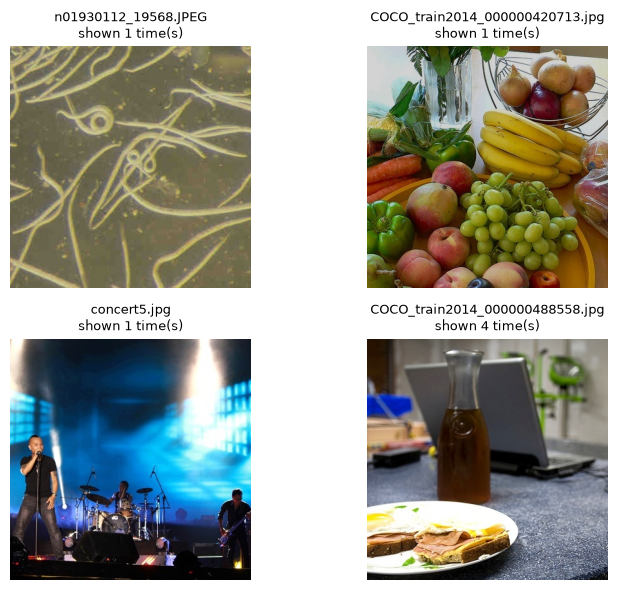

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
for ax, name in zip(axes.flat, example_names):
    path = IMAGE_DIR / name
    subset = events.loc[events.ImgName == name]
    if path.exists():
        with Image.open(path) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"{name}\nshown {int(subset.showings_of_image.iloc[0])} time(s)", fontsize=9)
    else:
        ax.text(0.5, 0.5, f"Not downloaded:\n{name}", ha="center", va="center")
    ax.axis("off")
plt.tight_layout()
plt.show()

- CSI1 has **5,254 showings** across 15 sessions and **4,916 different images**.
- Every region/hemisphere file has the same 5,254 rows. Across the ten files there are **1,685 voxel columns**: 680 left + 1,005 right.
- **4,803 images** were shown once. Of the other **113 image IDs**, 112 were shown four times and one was shown three times.
- The event files connect image names to session/run/trial.